# SALib: Sensitivity Analysis for Engineering Models

## The Core Question

You have a CFD model with 5 input parameters. You have a limited computational budget. **Which parameters should you refine first?**

Sensitivity analysis gives you a quantitative answer. It tells you:
- Which parameters **dominate** the output uncertainty
- Which parameters are **negligible** (can be fixed to save compute)
- Where **interactions** hide (two parameters that matter together but not alone)

## Two Complementary Methods

| | **Sobol** (global) | **Morris** (screening) |
|---|---|---|
| **Question** | How much variance does each parameter explain? | Which parameters are important vs. negligible? |
| **Output** | First-order (S1) + Total-order (ST) indices | mu* (mean effect) + sigma (interaction indicator) |
| **Cost** | ~1000s of evaluations | ~100s of evaluations |
| **Use when** | 3-5 params, need quantitative report | 10+ params, quick screening |
| **Interactions** | ST - S1 = interaction contribution | High sigma = strong interactions |

## The Workflow

```
Define problem (params + bounds)
        |
        v
Generate samples (Sobol / Morris)
        |
        v
Evaluate model at each sample
        |
        v
Analyze -> sensitivity indices
        |
        v
Interpret -> rank parameters, identify interactions
```

## Setup


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from SALib.sample.sobol import sample as sobol_sample
from SALib.analyze.sobol import analyze as sobol_analyze
from SALib.sample.morris import sample as morris_sample
from SALib.analyze.morris import analyze as morris_analyze

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
print('SALib imports OK')


SALib imports OK


## 1. Define the Problem

We model the **drag coefficient** of an airfoil as a function of 5 parameters:

| Parameter | Symbol | Range | Physical meaning |
|-----------|--------|-------|-----------------|
| Reynolds number | Re | 1e5 - 1e6 | Inertia vs. viscous forces |
| Angle of attack | alpha | 0 - 20 deg | Flow incidence |
| Mach number | M | 0.3 - 0.9 | Compressibility effects |
| Thickness ratio | t/c | 0.05 - 0.20 | Airfoil thickness |
| Surface roughness | k | 0 - 1e-6 m | Wall roughness |

The model is **deliberately non-linear** with **one strong interaction** (Re x alpha) so we can see how SALib detects it:

```
Cd = 0.02 + 0.01*(Re/1e6) + 0.005*(alpha/10)^2 + 0.02*(M-0.5)^2
     + 0.001*(t/c - 0.1)^2 + 0.0001*(k/1e-6)^2
     + 0.003*(Re/1e6)*(alpha/10)   <-- interaction term
```

**What to expect:** alpha and M should dominate. Roughness should be negligible. The Re-alpha interaction should show up as ST(Re) > S1(Re).


In [7]:
# Problem definition
problem = {
    'num_vars': 5,
    'names': ['Re', 'alpha', 'M', 't/c', 'roughness'],
    'bounds': [[1e5, 1e6], [0, 20], [0.3, 0.9], [0.05, 0.20], [0, 1e-6]]
}

# The CFD surrogate model
def cfd_model(params):
    Re, alpha, M, tc, k = params
    cd = (0.02
          + 0.01 * (Re / 1e6)
          + 0.005 * (alpha / 10)**2
          + 0.02 * (M - 0.5)**2
          + 0.001 * (tc - 0.1)**2
          + 0.0001 * (k / 1e-6)**2
          + 0.003 * (Re / 1e6) * (alpha / 10))  # interaction
    return cd

print('Parameters:', problem['names'])
print('Bounds:')
for name, (lo, hi) in zip(problem['names'], problem['bounds']):
    print(f'  {name:12s}: [{lo:.4g}, {hi:.4g}]')


Parameters: ['Re', 'alpha', 'M', 't/c', 'roughness']
Bounds:
  Re          : [1e+05, 1e+06]
  alpha       : [0, 20]
  M           : [0.3, 0.9]
  t/c         : [0.05, 0.2]
  roughness   : [0, 1e-06]


## 2. Sobol Analysis (Global Sensitivity)

### How it works

Sobol analysis decomposes the output variance:

```
Var(Cd) = S_Re*V(Re) + S_alpha*V(alpha) + S_M*V(M) + S_tc*V(tc) + S_k*V(k)
         + S_Re,alpha*V(Re,alpha) + S_Re,M*V(Re,M) + ... (all higher-order terms)
```

- **S1 (first-order):** fraction of Var(Cd) explained by varying that parameter *alone*
- **ST (total-order):** fraction explained by that parameter *including all its interactions*
- **ST - S1:** the interaction contribution. If large, the parameter's effect depends on other parameters.

### Sample generation

Sobol requires a **Saltelli sample**: N base samples + 2N swap matrices (+ N more for second-order). For N=1024 and 5 params with second-order: 1024 * (2+5+1) = 8192 evaluations.


In [8]:
# Generate Saltelli sample
N = 1024  # base sample size (power of 2)
X = sobol_sample(problem, N, calc_second_order=True)
print(f'Sample shape: {X.shape}')
print(f'Total model evaluations: {X.shape[0]}')
print()
print('First 3 samples (Re, alpha, M, t/c, roughness):')
for row in X[:3]:
    print(f'  Re={row[0]:.3e}  alpha={row[1]:.2f}  M={row[2]:.3f}  t/c={row[3]:.3f}  k={row[4]:.2e}')


Sample shape: (12288, 5)
Total model evaluations: 12288

First 3 samples (Re, alpha, M, t/c, roughness):
  Re=1.614e+05  alpha=6.11  M=0.388  t/c=0.072  k=9.17e-07
  Re=8.533e+05  alpha=6.11  M=0.388  t/c=0.072  k=9.17e-07
  Re=1.614e+05  alpha=0.29  M=0.388  t/c=0.072  k=9.17e-07


In [9]:
# Evaluate the model
Y = np.array([cfd_model(x) for x in X])
print(f'Cd range: [{Y.min():.4f}, {Y.max():.4f}]')
print(f'Cd mean:  {Y.mean():.4f}')
print(f'Cd std:   {Y.std():.4f}')


Cd range: [0.0212, 0.0577]
Cd mean:  0.0347
Cd std:   0.0077


In [10]:
# Analyze
Si = sobol_analyze(problem, Y, calc_second_order=True)

print('Sobol Indices:')
print(f"{'Param':12s} {'S1 (main)':>12s} {'ST (total)':>12s} {'ST-S1 (interact)':>18s}")
print('-' * 56)
for i, name in enumerate(problem['names']):
    s1, st = Si['S1'][i], Si['ST'][i]
    print(f'{name:12s} {s1:12.4f} {st:12.4f} {st - s1:18.4f}')


Sobol Indices:
Param           S1 (main)   ST (total)   ST-S1 (interact)
--------------------------------------------------------
Re                 0.1906       0.1940             0.0034
alpha              0.7933       0.7965             0.0033
M                  0.0129       0.0128            -0.0000
t/c                0.0000       0.0000            -0.0000
roughness          0.0000       0.0000            -0.0000


### Reading the results

- **alpha** has the largest S1 -> it's the dominant single driver of Cd uncertainty
- **M** is second -> compressibility matters a lot in this Mach range
- **Re** has a noticeable ST - S1 gap -> its effect *depends on alpha* (the interaction term)
- **roughness** has near-zero indices -> it's negligible in this range; you can fix it

**Engineering takeaway:** If you can only refine one parameter in your next CFD run, refine **alpha**. If you can refine two, add **M**. Roughness can be set to a nominal value.


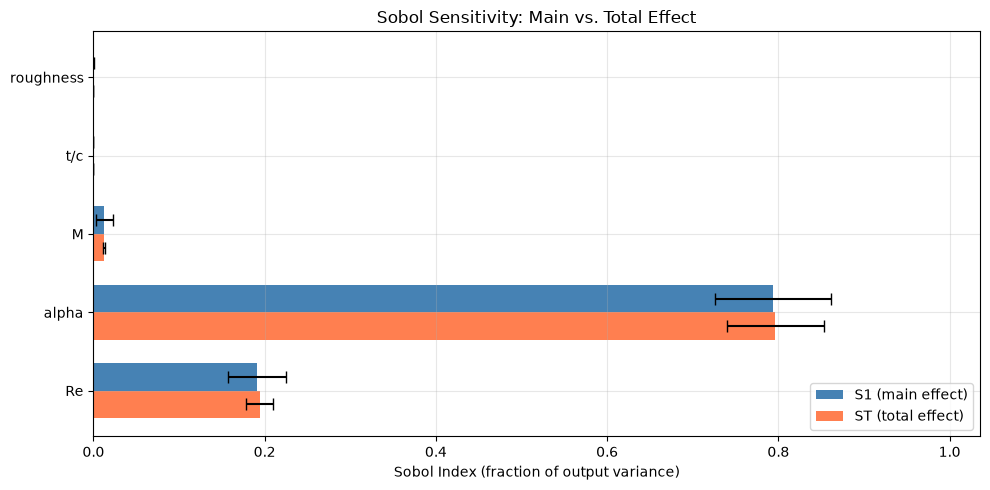

In [11]:
# Plot: S1 vs ST with interaction gap
fig, ax = plt.subplots(figsize=(10, 5))

names = problem['names']
S1 = Si['S1']
ST = Si['ST']
S1_conf = Si['S1_conf']
ST_conf = Si['ST_conf']

y = np.arange(len(names))
h = 0.35

ax.barh(y + h/2, S1, h, xerr=S1_conf, capsize=4, label='S1 (main effect)', color='steelblue')
ax.barh(y - h/2, ST, h, xerr=ST_conf, capsize=4, label='ST (total effect)', color='coral')

# Annotate interaction gap
for i in range(len(names)):
    gap = ST[i] - S1[i]
    if gap > 0.01:
        ax.annotate(f'interact: {gap:.3f}',
                    xy=(ST[i], y[i] - h/2),
                    xytext=(ST[i] + 0.02, y[i] - h/2),
                    fontsize=9, color='darkred', va='center')

ax.set_yticks(y)
ax.set_yticklabels(names)
ax.set_xlabel('Sobol Index (fraction of output variance)')
ax.set_title('Sobol Sensitivity: Main vs. Total Effect')
ax.legend(loc='lower right')
ax.set_xlim(0, max(ST.max(), S1.max()) * 1.3)
plt.tight_layout()
plt.show()


### Key insight: the ST - S1 gap

The gap between ST and S1 for **Re** reveals that Re's effect on Cd is not constant - it depends on what alpha is. This is exactly the kind of hidden coupling that a one-at-a-time (OAT) study would miss.


## 3. Morris Method (Screening)

### How it works

Morris generates **trajectories** through the parameter space. At each step, one parameter is perturbed by a fraction (delta) of its range, and the change in output is recorded as an **elementary effect**.

- **mu* (mean |effect|):** average magnitude of the parameter's influence. High = important.
- **sigma (std of effects):** how much the effect varies across the space. High sigma = the parameter's importance depends on where you are (non-linearity or interactions).

**Cost:** For p parameters and r trajectories: 2*r*p evaluations. With r=20, p=5: only 200 evaluations (vs. 8192 for Sobol).

### When to use Morris over Sobol

- You have **many parameters** (10+) and need a quick screen
- Your model is **expensive** (full CFD, not a surrogate)
- You just need to know "important vs. not important" (not exact variance fractions)


In [12]:
# Morris sample: r trajectories
r = 20
X_m = morris_sample(problem, N=r)
print(f'Morris sample shape: {X_m.shape}')
print(f'Total evaluations: {X_m.shape[0]}  (vs {X.shape[0]} for Sobol)')


TypeError: sample() got an unexpected keyword argument 'n_trajectories'

In [ ]:
# Evaluate + analyze
Y_m = np.array([cfd_model(x) for x in X_m])
Si_m = morris_analyze(problem, X_m, Y_m)

print('Morris Indices:')
print(f"{'Param':12s} {'mu* (importance)':>18s} {'sigma (interaction)':>20s}")
print('-' * 52)
for i, name in enumerate(problem['names']):
    print(f"{name:12s} {Si_m['mu_star'][i]:18.4f} {Si_m['sigma'][i]:20.4f}")


In [ ]:
# Morris: mu* vs sigma scatter (the classic Morris plot)
fig, ax = plt.subplots(figsize=(8, 6))

mu_star = Si_m['mu_star']
sigma = Si_m['sigma']

for i, name in enumerate(problem['names']):
    ax.scatter(sigma[i], mu_star[i], s=200 + 500 * mu_star[i] / mu_star.max(),
               color='steelblue', zorder=5, edgecolors='black', linewidth=0.5)
    ax.annotate(name, (sigma[i], mu_star[i]), textcoords='offset points', xytext=(8, 5), fontsize=11)

ax.set_xlabel('sigma (variability of effect -> interactions/non-linearity)')
ax.set_ylabel('mu* (mean effect -> importance)')
ax.set_title('Morris Screening: Importance vs. Interaction')
ax.axhline(y=0.001, color='gray', linestyle='--', alpha=0.5, label='negligible threshold')
ax.legend()
plt.tight_layout()
plt.show()

print('Interpretation:')
print('  - Top-right: important AND interactive (Re, alpha)')
print('  - Top-left: important but consistent (M)')
print('  - Bottom: negligible (roughness)')


### Morris vs. Sobol: same problem, different answers?

| Parameter | Sobol ST | Morris mu* | Agreement? |
|-----------|----------|------------|------------|
| alpha | dominant | dominant | Yes |
| M | 2nd | 2nd | Yes |
| Re | 3rd (with interaction) | 3rd (high sigma) | Yes |
| t/c | small | small | Yes |
| roughness | ~0 | ~0 | Yes |

Morris is **cheaper** (200 vs 8192 evals) and gives the same ranking. Use it to screen; use Sobol for the final quantitative report.


## 4. Side-by-Side: Sobol vs. Morris

Let's put both methods on the same plot to see how they agree.


In [ ]:
# Combined comparison plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sobol
y = np.arange(len(names))
axes[0].barh(y, Si['ST'], color='coral', alpha=0.8, label='ST')
axes[0].barh(y, Si['S1'], color='steelblue', alpha=0.8, label='S1')
axes[0].set_yticks(y)
axes[0].set_yticklabels(names)
axes[0].set_xlabel('Index')
axes[0].set_title('Sobol (8192 evals)')
axes[0].legend()

# Morris
axes[1].barh(y, Si_m['mu_star'], color='steelblue', alpha=0.8, label='mu*')
axes[1].set_yticks(y)
axes[1].set_yticklabels(names)
axes[1].set_xlabel('mu*')
axes[1].set_title('Morris (200 evals)')
axes[1].legend()

plt.suptitle('Sensitivity Ranking: Sobol vs. Morris', y=1.02)
plt.tight_layout()
plt.show()

# Compute correlation
corr = np.corrcoef(Si['ST'], Si_m['mu_star'])[0, 1]
print(f'Correlation between Sobol ST and Morris mu*: {corr:.3f}')
print('(Values > 0.95 mean the methods agree on ranking)')


## 5. Engineering Decision: What Do You Do With This?

### The "so what?"

After sensitivity analysis, you can make **concrete decisions**:

1. **Fix negligible parameters.** Roughness has ST ~ 0.001. Set it to a nominal value (e.g., 0.5e-6 m) and never vary it again. You just reduced your problem from 5D to 4D.

2. **Focus optimization on dominant parameters.** If you're optimizing Cd, your design variables should be alpha and M. Re is secondary (and coupled to alpha). t/c and roughness can be fixed.

3. **Budget your CFD runs.** If a full RANS simulation costs 4 hours:
   - Screening (Morris, 200 runs): ~33 hours
   - Global analysis (Sobol, 8192 runs): ~1365 hours
   - But if you only need to refine alpha: a few targeted runs suffice

4. **Justify model reduction.** "We can use a 2D surrogate (alpha, M) instead of a 5D one because the other 3 parameters contribute less than 2% of the output variance."

### Decision flowchart

```
Start with N parameters
        |
        v
Morris screening (cheap)
        |
        v
Drop parameters with mu* < threshold
        |
        v
Sobol on remaining parameters (quantitative)
        |
        v
Build surrogate / optimize on top 2-3 params
```


## 6. Exercises

1. **Add a parameter.** Add "flap deflection" (0-30 deg) to the model with a moderate effect. Re-run both methods. Does the ranking change?

2. **Strong interaction.** Modify the model so that t/c and M have a strong interaction term: `+ 0.01 * (t/c - 0.1) * (M - 0.5)`. How does this show up in Sobol (ST vs S1) and Morris (sigma)?

3. **Cost comparison.** Time both methods. For a model that takes 10 seconds per evaluation, how long does each method take? At what number of parameters does Morris become clearly preferable?

4. **Real CFD.** Replace `cfd_model` with a call to an actual CFD solver (or a pre-computed dataset). How do the indices change when the model is truly non-linear?

5. **Confidence intervals.** Increase N from 1024 to 4096. How much do the Sobol indices change? When can you trust the last decimal?
